# 04 — Modelagem | Bank Marketing

**Objetivo desta etapa:** treinar os modelos de árvore/boosting com parâmetros padrão, escorar **treino** e **teste (OOS)**, comparar as métricas para **avaliar overfitting** e, na seção 10, **tunar o LightGBM com Optuna**.

| Modelo | Biblioteca |
|---|---|
| Random Forest | scikit-learn |
| Gradient Boosting | scikit-learn |
| LightGBM | lightgbm |
| XGBoost | xgboost |
| CatBoost | catboost |

**Métricas:** KS, Gini, AUC (ordenação, não dependem de corte) e Recall, Precision, F1, Acurácia (dependem de um corte).

O **OOT é carregado, mas ainda não é escorado**. Ele entra depois da avaliação e da tunagem, junto com as visões de KS ao longo do tempo, decis e faixas de propensão.

## 1. Setup

In [41]:
!pip install -q catboost
import catboost

In [42]:
import warnings
warnings.filterwarnings('ignore')

import os, json, time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (roc_auc_score, roc_curve, recall_score, precision_score,
                             f1_score, accuracy_score)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')
SEED = 42

In [43]:
from google.colab import drive
drive.mount('/content/drive')
PASTA = r'/content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario'
PASTA_PREP = f'{PASTA}/Base/prep'
PASTA_MODELOS = f'{PASTA}/Modelos'

os.makedirs(PASTA_MODELOS, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Leitura das bases com as variáveis selecionadas

A lista vem do notebook 03 (`variaveis_selecionadas.json`), definida só no treino. Aqui ela é aplicada nas três bases.

In [44]:
TARGET = 'target'
with open(f'{PASTA_PREP}/variaveis_selecionadas.json') as f:
    FEATURES = json.load(f)

bases = {nome: pd.read_parquet(f'{PASTA_PREP}/{nome}.parquet') for nome in ['treino', 'teste']}

X_treino, y_treino = bases['treino'][FEATURES], bases['treino'][TARGET]
X_teste,  y_teste  = bases['teste'][FEATURES],  bases['teste'][TARGET]

pd.DataFrame({nome: {'linhas': len(d), 'variaveis': len(FEATURES), 'taxa_conversao': d[TARGET].mean()}
              for nome, d in bases.items()}).T

,linhas,variaveis,taxa_conversao
treino,"28,823.0000",12.0000,0.1127
teste,"12,353.0000",12.0000,0.1127


In [45]:
print(f'{len(FEATURES)} variáveis:', FEATURES)

12 variáveis: ['age', 'log_campaign', 'previous', 'te_job', 'te_marital', 'te_education', 'te_default', 'te_loan', 'te_contact', 'te_day_of_week', 'te_poutcome', 'te_faixa_idade']


## 3. Modelos

Parâmetros **padrão e moderados**, iguais em espírito para todos (sem tunagem ainda):
- ~300 árvores, `learning_rate` 0,05 nos boostings, profundidade limitada e um mínimo de linhas por folha. Isso já evita os casos mais óbvios de decorar o treino.
- **Sem balanceamento de classes** (`class_weight`, `scale_pos_weight`). Assim a saída do modelo continua sendo uma probabilidade real de conversão, o que importa para as faixas de propensão depois. O desbalanceamento é tratado na escolha do corte (seção 5).

In [46]:
modelos = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=50, n_jobs=-1, random_state=SEED),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3, min_samples_leaf=50,
        subsample=0.8, random_state=SEED),

    'LightGBM': LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31, max_depth=-1, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),

    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.8, eval_metric='auc', random_state=SEED, n_jobs=-1),

    'CatBoost': CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0),
}

## 4. Treino e escoragem (treino e teste)

In [47]:
scores = {'treino': pd.DataFrame(index=X_treino.index), 'teste': pd.DataFrame(index=X_teste.index)}
tempos = {}

for nome, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_treino, y_treino)
    tempos[nome] = time.time() - inicio
    scores['treino'][nome] = modelo.predict_proba(X_treino)[:, 1]
    scores['teste'][nome] = modelo.predict_proba(X_teste)[:, 1]
    print(f'{nome:<18} treinado em {tempos[nome]:5.1f}s')

Random Forest      treinado em  12.0s
Gradient Boosting  treinado em  27.2s
LightGBM           treinado em   1.4s
XGBoost            treinado em   0.8s
CatBoost           treinado em   3.2s


## 5. Métricas

**Ordenação (sem corte):**
- **AUC:** chance de um convertido receber score maior que um não convertido.
- **Gini** = 2 × AUC − 1.
- **KS:** maior distância entre as distribuições acumuladas do score de convertidos e não convertidos.

**Classificação (com corte):** Recall, Precision, F1 e Acurácia precisam de um corte para dizer quem é "1".
Com 6,7% de conversão, o corte padrão de 0,5 quase nunca classifica ninguém como 1. Por isso usamos o **corte do KS no treino** (o ponto de maior separação) e aplicamos **o mesmo corte** no teste.

> A acurácia engana em base desbalanceada: um modelo que diz "não converte" para todo mundo acerta 93%. Ela fica na tabela só para comparação.

In [48]:
def ks_score(y, p):
    fpr, tpr, cortes = roc_curve(y, p)
    i = np.argmax(tpr - fpr)
    return tpr[i] - fpr[i], cortes[i]

def metricas(y, p, corte):
    auc = roc_auc_score(y, p)
    ks, _ = ks_score(y, p)
    pred = (p >= corte).astype(int)
    return {'KS': ks, 'AUC': auc, 'Gini': 2 * auc - 1,
            'Recall': recall_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred), 'Acuracia': accuracy_score(y, pred)}

linhas, cortes = [], {}
for nome in modelos:
    _, cortes[nome] = ks_score(y_treino, scores['treino'][nome])        # corte definido no TREINO
    for base, y in [('treino', y_treino), ('teste', y_teste)]:
        linhas.append({'modelo': nome, 'base': base, 'corte': cortes[nome],
                       **metricas(y, scores[base][nome], cortes[nome])})

tab_metricas = pd.DataFrame(linhas).set_index(['modelo', 'base'])
tab_metricas.style.format('{:.4f}').background_gradient(subset=['KS', 'AUC', 'Gini'], cmap='Blues')

## 6. Diagnóstico de overfitting

Comparamos treino × teste. A referência mais usada em score é a **queda de Gini/KS**:

| Queda (pontos percentuais) | Leitura |
|---|---|
| até 5 p.p. | OK |
| 5 a 10 p.p. | Atenção |
| acima de 10 p.p. | Overfitting |

Também olhamos a **queda relativa** (`queda / valor no treino`), porque 5 p.p. pesam mais num Gini de 0,30 do que num de 0,70.

In [49]:
METRICAS = ['KS', 'AUC', 'Gini', 'Recall', 'Precision', 'F1', 'Acuracia']
tr = tab_metricas.xs('treino', level='base')[METRICAS]
te = tab_metricas.xs('teste', level='base')[METRICAS]

def status(queda_pp):
    return 'OK' if queda_pp <= 5 else 'Atenção' if queda_pp <= 10 else 'Overfitting'

diag = pd.DataFrame({
    'Gini_treino': tr['Gini'], 'Gini_teste': te['Gini'],
    'queda_Gini_pp': (tr['Gini'] - te['Gini']) * 100,
    'queda_Gini_rel': (tr['Gini'] - te['Gini']) / tr['Gini'],
    'KS_treino': tr['KS'], 'KS_teste': te['KS'],
    'queda_KS_pp': (tr['KS'] - te['KS']) * 100,
    'queda_KS_rel': (tr['KS'] - te['KS']) / tr['KS'],
})
diag['status'] = diag[['queda_Gini_pp', 'queda_KS_pp']].max(axis=1).apply(status)
diag = diag.sort_values('Gini_teste', ascending=False)

cor_status = {'OK': '#e5f5e0', 'Atenção': '#fff7bc', 'Overfitting': '#fdd0a2'}
diag.style.format({c: '{:.4f}' for c in ['Gini_treino', 'Gini_teste', 'KS_treino', 'KS_teste']}
                  | {c: '{:.1f}' for c in ['queda_Gini_pp', 'queda_KS_pp']}
                  | {c: '{:.1%}' for c in ['queda_Gini_rel', 'queda_KS_rel']}) \
          .apply(lambda r: [f'background-color: {cor_status[r["status"]]}'] * len(r), axis=1)

,Gini_treino,Gini_teste,queda_Gini_pp,queda_Gini_rel,KS_treino,KS_teste,queda_KS_pp,queda_KS_rel,status
modelo,,,,,,,,,
Random Forest,0.5126,0.4743,3.8,7.5%,0.3637,0.3461,1.8,4.8%,OK
CatBoost,0.5597,0.4717,8.8,15.7%,0.4083,0.3430,6.5,16.0%,Atenção
XGBoost,0.5663,0.4694,9.7,17.1%,0.4105,0.3424,6.8,16.6%,Atenção
Gradient Boosting,0.5145,0.4681,4.6,9.0%,0.3787,0.3396,3.9,10.3%,OK
LightGBM,0.7362,0.4543,28.2,38.3%,0.5661,0.3331,23.3,41.2%,Overfitting


In [50]:
# Diferença treino - teste em todas as métricas (positivo = treino melhor)
(tr - te).style.format('{:+.4f}').background_gradient(cmap='Reds', axis=None)

,KS,AUC,Gini,Recall,Precision,F1,Acuracia
modelo,,,,,,,
Random Forest,+0.0176,+0.0191,+0.0383,+0.0204,+0.0134,+0.0173,+0.0129
Gradient Boosting,+0.0391,+0.0232,+0.0464,+0.0318,+0.0290,+0.0347,+0.0262
LightGBM,+0.2330,+0.1410,+0.2819,+0.1968,+0.0805,+0.1148,+0.0593
XGBoost,+0.0681,+0.0484,+0.0969,+0.0369,+0.0537,+0.0606,+0.0530
CatBoost,+0.0653,+0.0440,+0.0880,+0.0167,+0.0376,+0.0433,+0.0477


### 6.1 Curvas ROC treino × teste

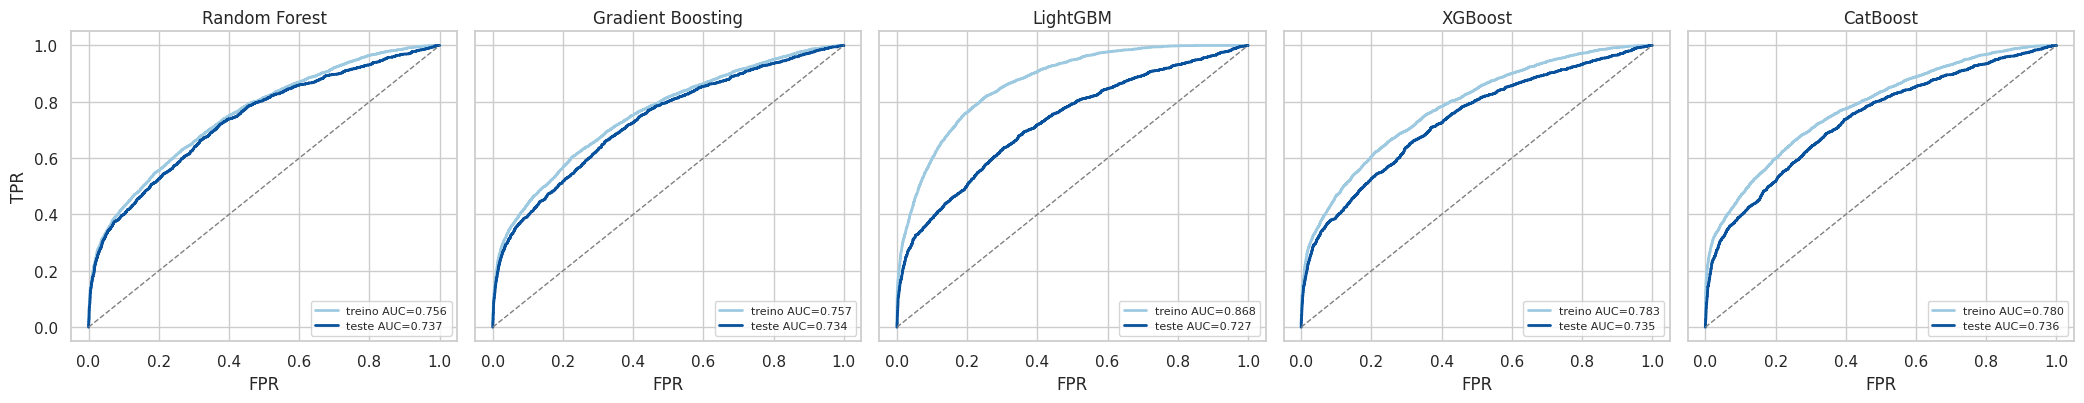

In [51]:
fig, axes = plt.subplots(1, len(modelos), figsize=(4.2 * len(modelos), 4.2), sharey=True)
for ax, nome in zip(axes, modelos):
    for base, y, cor in [('treino', y_treino, '#9ecae1'), ('teste', y_teste, '#08519c')]:
        fpr, tpr, _ = roc_curve(y, scores[base][nome])
        ax.plot(fpr, tpr, color=cor, lw=2, label=f'{base} AUC={roc_auc_score(y, scores[base][nome]):.3f}')
    ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1)
    ax.set_title(nome); ax.set_xlabel('FPR'); ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('TPR')
plt.tight_layout(); plt.show()

## 7. Estabilidade: validação cruzada no treino

Mede se o desempenho depende da sorte do sorteio. Cinco folds estratificados, **só no treino**.
Um desvio padrão alto entre os folds indica instabilidade; uma média da CV bem abaixo da AUC de treino confirma o overfitting.

In [52]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv = {}
for nome, modelo in modelos.items():
    aucs = cross_val_score(modelo, X_treino, y_treino, cv=skf, scoring='roc_auc', n_jobs=1)
    cv[nome] = {'AUC_cv_media': aucs.mean(), 'AUC_cv_desvio': aucs.std(),
                'AUC_treino': tr.loc[nome, 'AUC'], 'AUC_teste': te.loc[nome, 'AUC']}
tab_cv = pd.DataFrame(cv).T.sort_values('AUC_teste', ascending=False)
tab_cv['gap_treino_cv'] = tab_cv['AUC_treino'] - tab_cv['AUC_cv_media']
tab_cv

,AUC_cv_media,AUC_cv_desvio,AUC_treino,AUC_teste,gap_treino_cv
Random Forest,0.7369,0.0124,0.7563,0.7372,0.0194
CatBoost,0.7347,0.0124,0.7799,0.7359,0.0451
XGBoost,0.7128,0.0134,0.7831,0.7347,0.0704
Gradient Boosting,0.7385,0.0116,0.7572,0.7341,0.0187
LightGBM,0.7244,0.0116,0.8681,0.7271,0.1437


## 8. Importância das variáveis por modelo

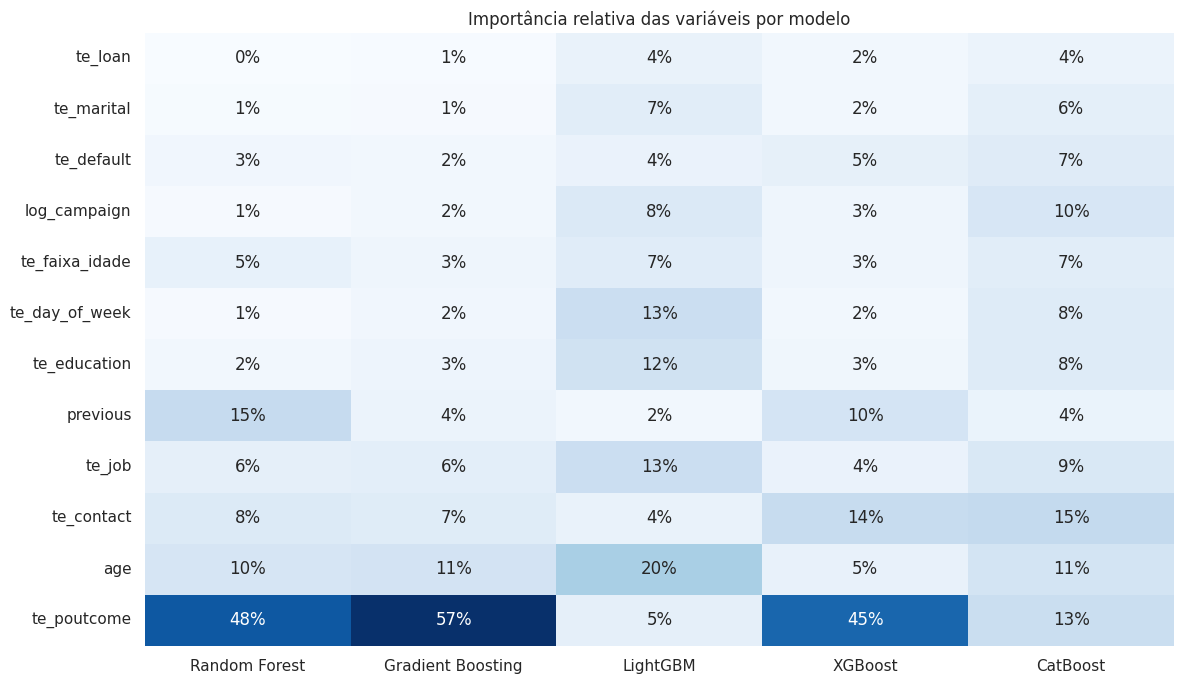

In [53]:
imp = pd.DataFrame({nome: pd.Series(m.feature_importances_, index=FEATURES) for nome, m in modelos.items()})
imp = imp / imp.sum()                                    # normaliza para comparar modelos
imp = imp.loc[imp.mean(axis=1).sort_values().index]

plt.figure(figsize=(12, 7))
sns.heatmap(imp, annot=True, fmt='.0%', cmap='Blues', cbar=False)
plt.title('Importância relativa das variáveis por modelo'); plt.tight_layout(); plt.show()

## 9. Resumo e salvamento

Ranking pela **AUC no teste**, com o status de overfitting. É a tabela base para decidir qual modelo seguir para a tunagem.

In [54]:
resumo = te[['KS', 'Gini', 'AUC', 'Recall', 'Precision', 'F1']].add_suffix('_teste') \
    .join(diag[['queda_Gini_pp', 'queda_KS_pp', 'status']]) \
    .join(tab_cv[['AUC_cv_media', 'AUC_cv_desvio']]) \
    .join(pd.Series(tempos, name='tempo_treino_s')) \
    .sort_values('AUC_teste', ascending=False)
resumo

,KS_teste,Gini_teste,AUC_teste,Recall_teste,Precision_teste,F1_teste,queda_Gini_pp,queda_KS_pp,status,AUC_cv_media,AUC_cv_desvio,tempo_treino_s
modelo,,,,,,,,,,,,
Random Forest,0.3461,0.4743,0.7372,0.6085,0.2180,0.3210,3.8254,1.7551,OK,0.7369,0.0124,11.9839
CatBoost,0.3430,0.4717,0.7359,0.6430,0.2123,0.3192,8.7985,6.5272,Atenção,0.7347,0.0124,3.2225
XGBoost,0.3424,0.4694,0.7347,0.5855,0.2179,0.3176,9.6854,6.8121,Atenção,0.7128,0.0134,0.8150
Gradient Boosting,0.3396,0.4681,0.7341,0.5740,0.2240,0.3222,4.6382,3.9069,OK,0.7385,0.0116,27.1651
LightGBM,0.3331,0.4543,0.7271,0.6200,0.2121,0.3161,28.1929,23.2965,Overfitting,0.7244,0.0116,1.3770


In [55]:
NOME_BASELINE = 'Gradient Boosting'
gb = modelos[NOME_BASELINE]

# 1. Modelo e artefatos
joblib.dump({
    'modelo': gb,
    'nome': NOME_BASELINE,
    'features': FEATURES,
    'params': gb.get_params(),
    'corte_ks_treino': cortes[NOME_BASELINE],
}, f'{PASTA_MODELOS}/modelo_baseline_random_forest.joblib')

# 2. Bases escoradas (score + target + safra)
base_scoradaTreino = pd.DataFrame({
    'score': gb.predict_proba(X_treino)[:, 1],
    TARGET: y_treino.values,
    'AnoMes': bases['treino']['AnoMes'].values,
})
base_scoradaTeste = pd.DataFrame({
    'score': gb.predict_proba(X_teste)[:, 1],
    TARGET: y_teste.values,
    'AnoMes': bases['teste']['AnoMes'].values,
})

base_scoradaTreino['qtd'] = 1
base_scoradaTeste['qtd'] = 1

base_scoradaTreino.to_excel(f'{PASTA_MODELOS}/scores_treino_baseline_random_forest.xlsx', index=False)
base_scoradaTeste.to_excel(f'{PASTA_MODELOS}/scores_teste_baseline_random_forest.xlsx', index=False)

#### Testando ordenação do score do modelo baseline
  - taxa de Conversão por decil do score na base de teste

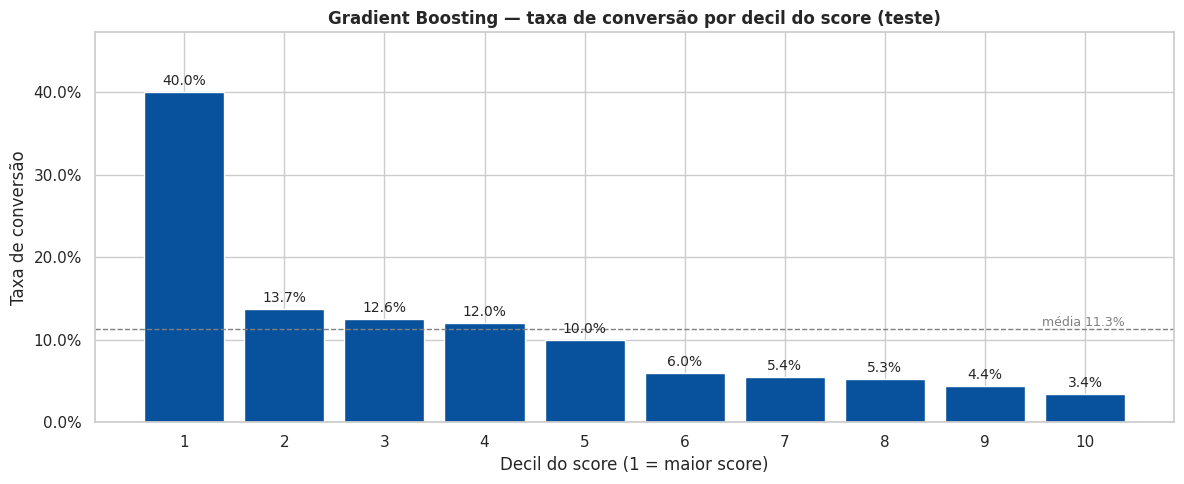

,qtd,conversoes,score_min,score_max,taxa_conversao,lift,captura_acumulada
decil,,,,,,,
1,"1,236",495,0.1687,0.9009,40.05%,3.55,35.6%
2,"1,235",169,0.1339,0.1686,13.68%,1.21,47.7%
3,"1,235",155,0.1177,0.1338,12.55%,1.11,58.8%
4,"1,235",148,0.1005,0.1177,11.98%,1.06,69.5%
5,"1,236",123,0.0842,0.1005,9.95%,0.88,78.3%
6,"1,235",74,0.0656,0.0842,5.99%,0.53,83.6%
7,"1,235",67,0.0549,0.0655,5.43%,0.48,88.4%
8,"1,235",65,0.0459,0.0549,5.26%,0.47,93.1%
9,"1,235",54,0.0382,0.0459,4.37%,0.39,97.0%


In [56]:
# ===== Taxa de conversão por decil do score — base de teste =====
MODELO_DECIL = 'Gradient Boosting'

dec = pd.DataFrame({'score': scores['teste'][MODELO_DECIL].values, 'target': y_teste.values})
dec['decil'] = pd.qcut(dec['score'].rank(method='first', ascending=False), 10, labels=range(1, 11))

tab_decil = dec.groupby('decil', observed=True).agg(
    qtd=('target', 'size'), conversoes=('target', 'sum'),
    score_min=('score', 'min'), score_max=('score', 'max'))
tab_decil['taxa_conversao'] = tab_decil['conversoes'] / tab_decil['qtd']
tab_decil['lift'] = tab_decil['taxa_conversao'] / dec['target'].mean()
tab_decil['captura_acumulada'] = tab_decil['conversoes'].cumsum() / tab_decil['conversoes'].sum()

taxa_media = dec['target'].mean()
fig, ax = plt.subplots(figsize=(12, 5))
barras = ax.bar(tab_decil.index.astype(str), tab_decil['taxa_conversao'], color='#08519c')
ax.bar_label(barras, labels=[f'{v:.1%}' for v in tab_decil['taxa_conversao']], padding=3, fontsize=10)
ax.axhline(taxa_media, ls='--', color='grey', lw=1)
ax.text(9.4, taxa_media, f'média {taxa_media:.1%}', va='bottom', ha='right', color='grey', fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, tab_decil['taxa_conversao'].max() * 1.18)
ax.set_xlabel('Decil do score (1 = maior score)')
ax.set_ylabel('Taxa de conversão')
ax.set_title(f'{MODELO_DECIL} — taxa de conversão por decil do score (teste)', fontweight='bold')
plt.tight_layout(); plt.show()

display(tab_decil.style.format({'qtd': '{:,.0f}', 'conversoes': '{:,.0f}', 'score_min': '{:.4f}',
                                'score_max': '{:.4f}', 'taxa_conversao': '{:.2%}', 'lift': '{:.2f}',
                                'captura_acumulada': '{:.1%}'})
                  .background_gradient(subset=['taxa_conversao'], cmap='RdYlGn'))

## 10. Tunagem do LightGBM com Optuna

**Objetivo:** encontrar parâmetros que mantenham a AUC do LightGBM e reduzam o overfitting.

**Como funciona cada trial:**
1. O Optuna sorteia uma combinação de parâmetros (amostrador TPE, que aprende com os trials anteriores).
2. Validação cruzada de 5 folds **só no treino**. Em cada fold, o modelo treina com early stopping na parte de validação do próprio fold, até 2.000 árvores. Assim o nº de árvores é escolhido automaticamente.
3. O trial recebe uma nota:

`nota = AUC média de validação − PENALIDADE × max(0, gap − 0,04)`

em que `gap` = AUC de treino − AUC de validação, na média dos folds. Até 0,04 de gap de AUC (≈ 8 p.p. de Gini, abaixo do limite de 10 p.p. de overfitting) não há punição; acima disso, a nota cai. Assim o Optuna procura modelos que generalizam, e não só a maior AUC.

> **O teste não participa da tunagem.** Ele só é usado no fim, para conferir o modelo escolhido.

In [57]:
!pip install -q optuna
import optuna

import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [58]:
N_TRIALS = 300                 # máximo; a parada antecipada costuma encerrar antes
PACIENCIA = 50                # trials seguidos sem melhora de AUC para parar
MIN_MELHORA = 0.0005           # melhora mínima de AUC que conta como "melhorou"
PENALIDADE_GAP = 1.0
GAP_TOLERADO = 0.03
PENALIDADE_INVERSAO = 0.005    # cada inversão nos decis out-of-fold tira 0,005 da nota
skf_opt = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

MONOTONIA = [1 if f.startswith('te_') else -1 if f == 'log_campaign' else 0 for f in FEATURES]
print(dict(zip(FEATURES, MONOTONIA)))

def inversoes_decil(y, score, n=10):
    d = pd.DataFrame({'score': score, 'y': np.asarray(y)})
    d['decil'] = pd.qcut(d['score'].rank(method='first', ascending=False), n, labels=False)
    taxa = d.groupby('decil')['y'].mean()
    return int((taxa.diff() > 0).sum())


def objetivo(trial):
    params = {
        'objective': 'binary', 'metric': 'auc', 'verbosity': -1, 'random_state': SEED,
        'n_estimators': 3000, 'subsample_freq': 1,
        'monotone_constraints': MONOTONIA, 'monotone_constraints_method': 'advanced',
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.05, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 8, 20),
        'max_depth':         trial.suggest_int('max_depth', 2, 5),
        'min_child_samples': trial.suggest_int('min_child_samples', 200, 500),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-2, 20, log=True),
        'min_split_gain':    trial.suggest_float('min_split_gain', 0.5, 2.0),
    }

    oof = np.zeros(len(y_treino))           # score de validação de cada linha do treino
    auc_tr, arvores = [], []
    for idx_tr, idx_va in skf_opt.split(X_treino, y_treino):
        Xa, Xv = X_treino.iloc[idx_tr], X_treino.iloc[idx_va]
        ya, yv = y_treino.iloc[idx_tr], y_treino.iloc[idx_va]
        m = LGBMClassifier(**params)
        m.fit(Xa, ya, eval_set=[(Xv, yv)], eval_metric='auc',
              callbacks=[lgb.early_stopping(50, verbose=False)])
        oof[idx_va] = m.predict_proba(Xv)[:, 1]
        auc_tr.append(roc_auc_score(ya, m.predict_proba(Xa)[:, 1]))
        arvores.append(m.best_iteration_)

    auc_va = roc_auc_score(y_treino, oof)
    gap = np.mean(auc_tr) - auc_va
    inv = inversoes_decil(y_treino, oof)

    trial.set_user_attr('auc_validacao', auc_va)
    trial.set_user_attr('auc_treino', np.mean(auc_tr))
    trial.set_user_attr('gap', gap)
    trial.set_user_attr('inversoes_oof', inv)
    trial.set_user_attr('n_estimators', int(np.mean(arvores)))
    return auc_va - PENALIDADE_GAP * max(0, gap - GAP_TOLERADO) - PENALIDADE_INVERSAO * inv


class ParadaSemMelhora:
    """Para o estudo quando a AUC de validação não melhora por `paciencia` trials seguidos."""
    def __init__(self, paciencia, min_melhora=0.0):
        self.paciencia, self.min_melhora = paciencia, min_melhora
        self.melhor_auc, self.trial_melhor = -np.inf, 0

    def __call__(self, study, trial):
        if trial.state != optuna.trial.TrialState.COMPLETE:
            return
        auc = trial.user_attrs['auc_validacao']
        if auc > self.melhor_auc + self.min_melhora:
            self.melhor_auc, self.trial_melhor = auc, trial.number
        elif trial.number - self.trial_melhor >= self.paciencia:
            print(f'\nParada antecipada no trial #{trial.number}: {self.paciencia} trials sem melhora de AUC '
                  f'(melhor AUC {self.melhor_auc:.4f} no trial #{self.trial_melhor})')
            study.stop()

{'age': 0, 'log_campaign': -1, 'previous': 0, 'te_job': 1, 'te_marital': 1, 'te_education': 1, 'te_default': 1, 'te_loan': 1, 'te_contact': 1, 'te_day_of_week': 1, 'te_poutcome': 1, 'te_faixa_idade': 1}


In [59]:
estudo = optuna.create_study(direction='maximize', study_name='lgbm_bank_marketing',
                             sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=15))
inicio = time.time()
estudo.optimize(objetivo, n_trials=N_TRIALS, show_progress_bar=True,
                callbacks=[ParadaSemMelhora(PACIENCIA, MIN_MELHORA)])
print(f'{len(estudo.trials)} trials em {(time.time() - inicio) / 60:.1f} min')

melhor = estudo.best_trial
print(f"\nMelhor trial: #{melhor.number}")
print(f"  nota                  : {melhor.value:.4f}")
print(f"  AUC validação (OOF)   : {melhor.user_attrs['auc_validacao']:.4f}")
print(f"  AUC treino (CV)       : {melhor.user_attrs['auc_treino']:.4f}")
print(f"  gap treino-validação  : {melhor.user_attrs['gap']:.4f}")
print(f"  inversões nos decis   : {melhor.user_attrs['inversoes_oof']}")
print(f"  nº de árvores (média) : {melhor.user_attrs['n_estimators']}")
pd.Series(melhor.params).to_frame('valor')

  0%|          | 0/300 [00:00<?, ?it/s]


Parada antecipada no trial #69: 50 trials sem melhora de AUC (melhor AUC 0.7376 no trial #19)
70 trials em 10.2 min

Melhor trial: #38
  nota                  : 0.7377
  AUC validação (OOF)   : 0.7377
  AUC treino (CV)       : 0.7486
  gap treino-validação  : 0.0108
  inversões nos decis   : 0
  nº de árvores (média) : 263


,valor
learning_rate,0.0212
num_leaves,11.0000
max_depth,5.0000
min_child_samples,221.0000
subsample,0.7769
colsample_bytree,0.6974
reg_alpha,0.0942
reg_lambda,5.7888
min_split_gain,0.8010


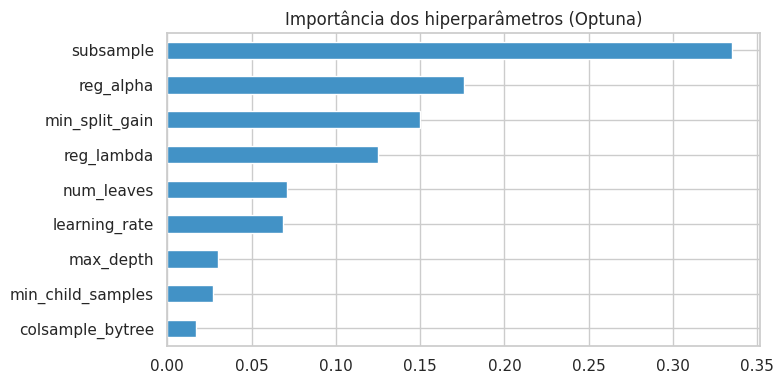

In [60]:
# Quais parâmetros mais influenciaram a nota
imp_params = pd.Series(optuna.importance.get_param_importances(estudo)).sort_values()
imp_params.plot.barh(color='#4292c6', figsize=(8, 4), title='Importância dos hiperparâmetros (Optuna)')
plt.tight_layout(); plt.show()

### 10.2 Modelo final: treino completo e escoragem

O modelo final usa os melhores parâmetros e o **nº médio de árvores** encontrado pelo early stopping nos folds. Ele é treinado no treino inteiro, sem early stopping (não há mais um fold de validação), e então escoramos treino e teste.

In [61]:
params_finais = {**melhor.params, 'n_estimators': melhor.user_attrs['n_estimators'],
                 'subsample_freq': 1, 'random_state': SEED, 'verbose': -1,
                 'monotone_constraints': MONOTONIA, 'monotone_constraints_method': 'advanced'}
lgbm_tunado = LGBMClassifier(**params_finais).fit(X_treino, y_treino)

scores['treino']['LightGBM tunado'] = lgbm_tunado.predict_proba(X_treino)[:, 1]
scores['teste']['LightGBM tunado'] = lgbm_tunado.predict_proba(X_teste)[:, 1]
_, cortes['LightGBM tunado'] = ks_score(y_treino, scores['treino']['LightGBM tunado'])
params_finais

{'learning_rate': 0.021249557501557114,
 'num_leaves': 11,
 'max_depth': 5,
 'min_child_samples': 221,
 'subsample': 0.7769498854876971,
 'colsample_bytree': 0.6973686020781145,
 'reg_alpha': 0.09417475066177278,
 'reg_lambda': 5.788836939449613,
 'min_split_gain': 0.8010411282653083,
 'n_estimators': 263,
 'subsample_freq': 1,
 'random_state': 42,
 'verbose': -1,
 'monotone_constraints': [0, -1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
 'monotone_constraints_method': 'advanced'}

### 10.3 Comparação: LightGBM tunado × baseline

Mesmas métricas e mesma regra de overfitting da seção 6. Referências: o LightGBM padrão e o Gradient Boosting (melhor equilíbrio do baseline).

In [62]:
comparar = ['LightGBM', 'Gradient Boosting', 'LightGBM tunado']
linhas = []
for nome in comparar:
    for base, y in [('treino', y_treino), ('teste', y_teste)]:
        linhas.append({'modelo': nome, 'base': base, 'corte': cortes[nome],
                       **metricas(y, scores[base][nome], cortes[nome])})
tab_comp = pd.DataFrame(linhas).set_index(['modelo', 'base'])

tr_c = tab_comp.xs('treino', level='base')
te_c = tab_comp.xs('teste', level='base')
diag_comp = pd.DataFrame({
    'AUC_treino': tr_c['AUC'], 'AUC_teste': te_c['AUC'],
    'Gini_treino': tr_c['Gini'], 'Gini_teste': te_c['Gini'],
    'queda_Gini_pp': (tr_c['Gini'] - te_c['Gini']) * 100,
    'KS_treino': tr_c['KS'], 'KS_teste': te_c['KS'],
    'queda_KS_pp': (tr_c['KS'] - te_c['KS']) * 100,
}).loc[comparar]
diag_comp['status'] = diag_comp[['queda_Gini_pp', 'queda_KS_pp']].max(axis=1).apply(status)

display(tab_comp.style.format('{:.4f}').background_gradient(subset=['KS', 'AUC', 'Gini'], cmap='Blues'))
diag_comp.style.format({c: '{:.4f}' for c in diag_comp.columns if c not in ['queda_Gini_pp', 'queda_KS_pp', 'status']}
                       | {'queda_Gini_pp': '{:.1f}', 'queda_KS_pp': '{:.1f}'}) \
         .apply(lambda r: [f'background-color: {cor_status[r["status"]]}'] * len(r), axis=1)

,AUC_treino,AUC_teste,Gini_treino,Gini_teste,queda_Gini_pp,KS_treino,KS_teste,queda_KS_pp,status
modelo,,,,,,,,,
LightGBM,0.8681,0.7271,0.7362,0.4543,28.2,0.5661,0.3331,23.3,Overfitting
Gradient Boosting,0.7572,0.7341,0.5145,0.4681,4.6,0.3787,0.3396,3.9,OK
LightGBM tunado,0.7479,0.7371,0.4959,0.4743,2.2,0.3580,0.3448,1.3,OK


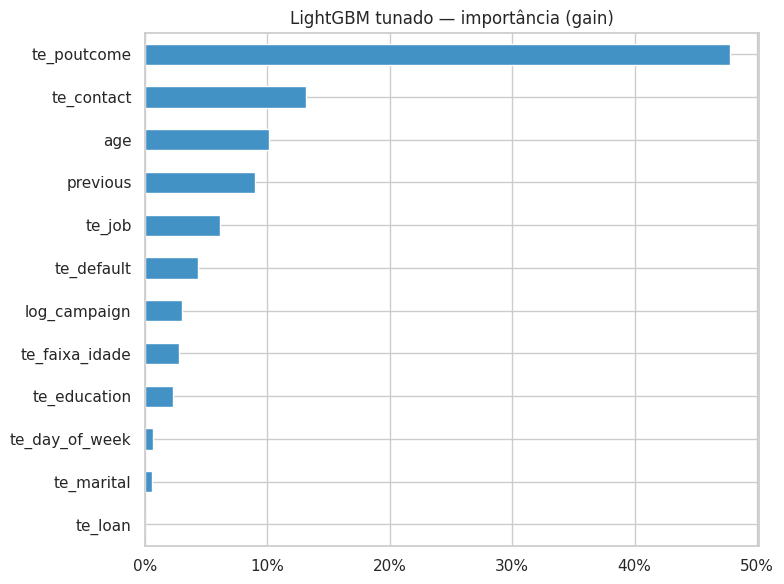

In [63]:
# Importância das variáveis no modelo tunado (ganho)
imp_tun = pd.Series(lgbm_tunado.booster_.feature_importance(importance_type='gain'), index=FEATURES)
(imp_tun / imp_tun.sum()).sort_values().plot.barh(color='#4292c6', figsize=(8, 6),
                                                   title='LightGBM tunado — importância (gain)')
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout(); plt.show()

In [64]:
# 2. Bases escoradas (score + target + safra)
score_train = lgbm_tunado.predict_proba(X_treino)[:, 1]
score_test  = lgbm_tunado.predict_proba(X_teste)[:, 1]

base_scoradaTreino = pd.DataFrame({
    'score': score_train,                                     # usar em decis, percentis e faixas
    'score_1000': np.round(score_train * 1000).astype(int),   # só para exibir
    TARGET: y_treino.values,
    'AnoMes': bases['treino']['AnoMes'].values,
})
base_scoradaTeste = pd.DataFrame({
    'score': score_test,
    'score_1000': np.round(score_test * 1000).astype(int),
    TARGET: y_teste.values,
    'AnoMes': bases['teste']['AnoMes'].values,
})

base_scoradaTreino['qtd'] = 1
base_scoradaTeste['qtd'] = 1

base_scoradaTreino.to_excel(f'{PASTA_MODELOS}/scores_treino_baseline_lgbmOptuna.xlsx', index=False)
base_scoradaTeste.to_excel(f'{PASTA_MODELOS}/scores_teste_baseline_lgbmOptuna.xlsx', index=False)

Ordenação do score
  - Taxa de coversão por decil do score

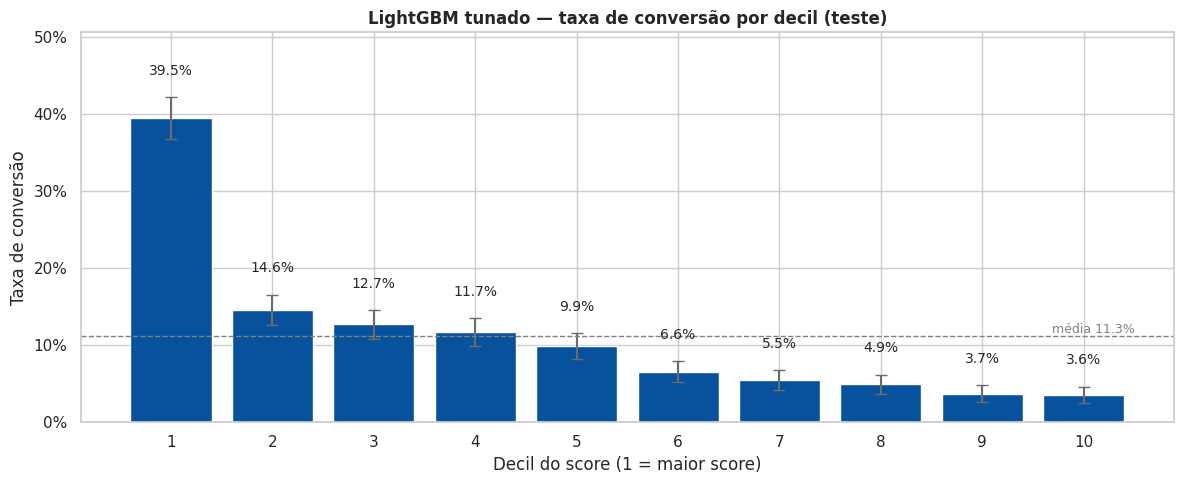

,qtd,conversoes,score_min,score_max,taxa_conversao,ic95,lift,captura_acumulada
decil,,,,,,,,
1,"1,236",488,0.1699,0.8137,39.48%,±2.73%,3.50,35.1%
2,"1,235",180,0.1331,0.1699,14.57%,±1.97%,1.29,48.0%
3,"1,235",157,0.1162,0.1331,12.71%,±1.86%,1.13,59.3%
4,"1,235",145,0.0986,0.1162,11.74%,±1.80%,1.04,69.7%
5,"1,236",122,0.0807,0.0986,9.87%,±1.66%,0.88,78.4%
6,"1,235",81,0.0637,0.0807,6.56%,±1.38%,0.58,84.3%
7,"1,235",68,0.0550,0.0637,5.51%,±1.27%,0.49,89.2%
8,"1,235",61,0.0475,0.0550,4.94%,±1.21%,0.44,93.5%
9,"1,235",46,0.0390,0.0475,3.72%,±1.06%,0.33,96.8%


In [65]:
NOME_MODELO = 'LightGBM tunado'
N_GRUPOS = 10
base_scoradaTeste['decil'] = pd.qcut(base_scoradaTeste['score'].rank(method='first', ascending=False),
                                     N_GRUPOS, labels=range(1, N_GRUPOS + 1))

tab_decil = base_scoradaTeste.groupby('decil', observed=True).agg(
    qtd=(TARGET, 'size'), conversoes=(TARGET, 'sum'), score_min=('score', 'min'), score_max=('score', 'max'))
taxa_media = base_scoradaTeste[TARGET].mean()
tab_decil['taxa_conversao'] = tab_decil['conversoes'] / tab_decil['qtd']
tab_decil['ic95'] = 1.96 * np.sqrt(tab_decil['taxa_conversao'] * (1 - tab_decil['taxa_conversao']) / tab_decil['qtd'])
tab_decil['lift'] = tab_decil['taxa_conversao'] / taxa_media
tab_decil['captura_acumulada'] = tab_decil['conversoes'].cumsum() / tab_decil['conversoes'].sum()
t, ic = tab_decil['taxa_conversao'].values, tab_decil['ic95'].values
inversoes_sig = int(sum((t[i + 1] - ic[i + 1]) > (t[i] + ic[i]) for i in range(len(t) - 1)))

fig, ax = plt.subplots(figsize=(12, 5))
x = tab_decil.index.astype(str)
barras = ax.bar(x, tab_decil['taxa_conversao'], yerr=tab_decil['ic95'], capsize=4, color='#08519c', ecolor='#6b6b6b')
ax.bar_label(barras, labels=[f'{v:.1%}' for v in tab_decil['taxa_conversao']], padding=14, fontsize=10)
ax.axhline(taxa_media, ls='--', color='grey', lw=1)
ax.text(len(x) - 0.5, taxa_media, f'média {taxa_media:.1%}', va='bottom', ha='right', color='grey', fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, (tab_decil['taxa_conversao'] + tab_decil['ic95']).max() * 1.2)
ax.set_xlabel('Decil do score (1 = maior score)'); ax.set_ylabel('Taxa de conversão')
ax.set_title(f'{NOME_MODELO} — taxa de conversão por decil (teste)', fontweight='bold')
plt.tight_layout(); plt.show()

display(tab_decil.style.format({'qtd': '{:,.0f}', 'conversoes': '{:,.0f}', 'score_min': '{:.4f}', 'score_max': '{:.4f}',
                                'taxa_conversao': '{:.2%}', 'ic95': '±{:.2%}', 'lift': '{:.2f}', 'captura_acumulada': '{:.1%}'})
                  .background_gradient(subset=['taxa_conversao'], cmap='RdYlGn'))

### 10.4 Salvar

In [66]:
joblib.dump({'modelo': lgbm_tunado, 'params': params_finais, 'corte_ks_treino': cortes['LightGBM tunado'],
             'features': FEATURES, 'cv_auc_validacao': melhor.user_attrs['auc_validacao']},
            f'{PASTA_MODELOS}/lgbm_tunado.joblib')
joblib.dump(estudo, f'{PASTA_MODELOS}/optuna_estudo_lgbm.joblib')

diag_comp.to_csv(f'{PASTA_MODELOS}/comparacao_lgbm_tunado.csv')
print('Salvo em', PASTA_MODELOS)

Salvo em /content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Modelos


## Construindo as faixas de risco

  qcut na base de treino, para construir as faixas de risco
  
    - replicar as faixas de risco no teste

In [67]:
#Percentis do score - base de treino escorada
base_scoradaTreino['percentil'] = pd.qcut(
    base_scoradaTreino['score_1000'].rank(method='first', ascending=False), 100, labels=range(1, 101))

tab_percentil = base_scoradaTreino.groupby('percentil', observed=True).agg(
    qtd_pessoas=(TARGET, 'size'),
    qtd_converteram=(TARGET, 'sum'),
    score_min=('score_1000', 'min'),
    score_max=('score_1000', 'max'),
)
tab_percentil['taxa_conversao'] = tab_percentil['qtd_converteram'] / tab_percentil['qtd_pessoas']

print(f"Total: {tab_percentil['qtd_pessoas'].sum():,} pessoas | {tab_percentil['qtd_converteram'].sum():,} conversões")
tab_percentil

PASTA_FAIXARISCO = f'{PASTA}/Faixas de Risco'
tab_percentil.to_excel(f'{PASTA_FAIXARISCO}/construcao_faixas_risco.xlsx', index=False)
print('Salvo em', PASTA_FAIXARISCO)

Total: 28,823 pessoas | 3,247 conversões
Salvo em /content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Faixas de Risco


## Replicando as faixas de Risco

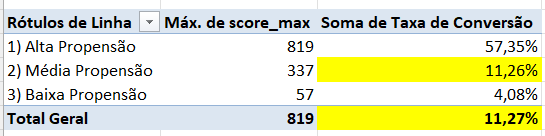

In [68]:
# ===== 1. Faixas de propensão (cortes do treino, escala score_1000) =====
def faixa_propensao(base):
    condicoes = [
        base['score_1000'] > 337,                                   # Alta: acima de 337
        (base['score_1000'] > 57) & (base['score_1000'] <= 337),    # Média: 58 a 337
        base['score_1000'] <= 57,                                   # Baixa: até 57
    ]
    rotulos = ['1) Alta propensao', '2) Media propensao', '3) Baixa propensao']
    return np.select(condicoes, rotulos, default='Sem faixa')

# ===== 2. Períodos: meses vizinhos agrupados (2008 a 2010) =====
MAPA_PERIODO = {
    200805: '2008-05/06', 200806: '2008-05/06',
    200807: '2008-07/08', 200808: '2008-07/08',
    200810: '2008-10/12', 200811: '2008-10/12', 200812: '2008-10/12',
    200903: '2009-03/05', 200904: '2009-03/05', 200905: '2009-03/05',
    200906: '2009-06/08', 200907: '2009-06/08', 200908: '2009-06/08',
    200909: '2009-09/12', 200910: '2009-09/12', 200911: '2009-09/12', 200912: '2009-09/12',
    201003: '2010-03/06', 201004: '2010-03/06', 201005: '2010-03/06', 201006: '2010-03/06',
    201007: '2010-07/11', 201008: '2010-07/11', 201009: '2010-07/11', 201010: '2010-07/11', 201011: '2010-07/11',
}

bases_faixa = {'treino': base_scoradaTreino, 'teste': base_scoradaTeste}
agrupadas = []
for nome, base in bases_faixa.items():
    base['faixa_propensao'] = faixa_propensao(base)
    base['periodo'] = base['AnoMes'].map(MAPA_PERIODO)
    assert (base['faixa_propensao'] != 'Sem faixa').all(), f'{nome}: há linhas sem faixa'
    assert base['periodo'].notna().all(), f'{nome}: há AnoMes fora do MAPA_PERIODO'

    # Base na granularidade atual (uma linha por cliente), com a coluna periodo
    base.to_excel(f'{PASTA_FAIXARISCO}/base_scorada{nome.capitalize()}_faixasRisco.xlsx', index=False)

    # Base agrupada: período x faixa
    g = base.groupby(['periodo', 'faixa_propensao'], as_index=False).agg(
        qtd_publico=(TARGET, 'size'),
        qtd_converteram=(TARGET, 'sum'))
    g.insert(0, 'base', nome)
    agrupadas.append(g)

base_agrupada = pd.concat(agrupadas, ignore_index=True)
for nome, g in base_agrupada.groupby('base'):
    g.to_excel(f'{PASTA_FAIXARISCO}/base_agrupada_periodo_faixa_{nome}.xlsx', index=False)

# Conferência: pessoas por período e faixa no teste
display(base_agrupada[base_agrupada['base'] == 'teste']
        .pivot(index='periodo', columns='faixa_propensao', values='qtd_publico'))
print('Salvo em', PASTA_FAIXARISCO)

faixa_propensao,1) Alta propensao,2) Media propensao,3) Baixa propensao
periodo,,,
2008-05/06,NaN,658.0000,"3,018.0000"
2008-07/08,1.0000,"2,858.0000",661.0000
2008-10/12,19.0000,982.0000,121.0000
2009-03/05,119.0000,"2,188.0000",264.0000
2009-06/08,109.0000,374.0000,16.0000
2009-09/12,122.0000,238.0000,15.0000
2010-03/06,99.0000,143.0000,24.0000
2010-07/11,137.0000,172.0000,15.0000


Salvo em /content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Faixas de Risco


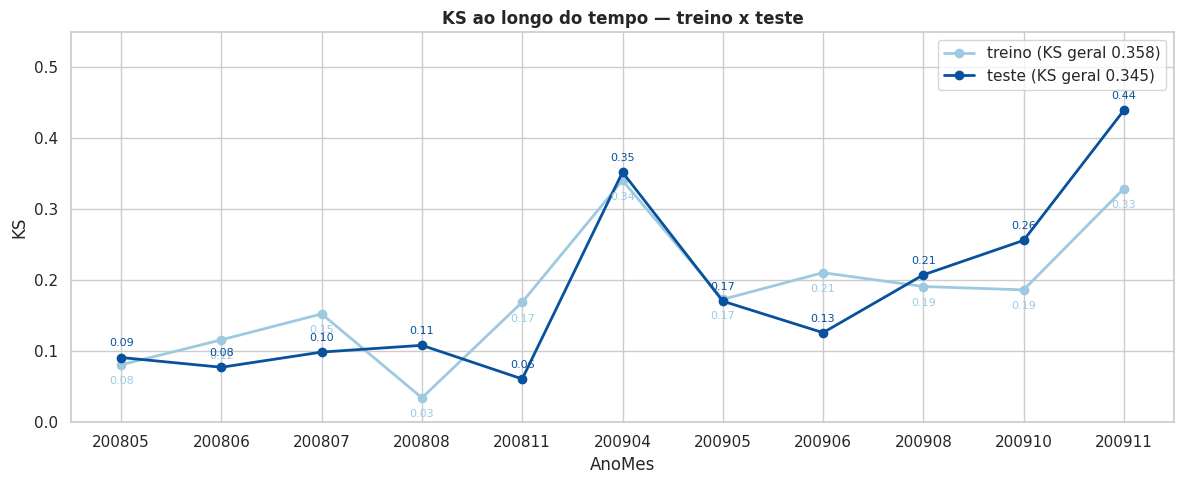

In [69]:
# ===== KS por safra: treino x teste =====
MIN_QTD_SAFRA = 100        # safras com menos linhas que isso (em qualquer base) ficam de fora do gráfico

def ks_por_safra(base):
    linhas = []
    for safra, g in base.groupby('AnoMes'):
        valido = len(g) >= MIN_QTD_SAFRA and g[TARGET].nunique() == 2
        linhas.append({'AnoMes': safra, 'qtd': len(g), 'conversoes': int(g[TARGET].sum()),
                       'ks': ks_score(g[TARGET], g['score'])[0] if valido else np.nan})
    return pd.DataFrame(linhas).set_index('AnoMes')

ks_safra = ks_por_safra(base_scoradaTreino).add_suffix('_treino').join(
           ks_por_safra(base_scoradaTeste).add_suffix('_teste'), how='outer')
ks_plot = ks_safra.dropna(subset=['ks_treino', 'ks_teste'])
ks_geral = {'treino': ks_score(base_scoradaTreino[TARGET], base_scoradaTreino['score'])[0],
            'teste':  ks_score(base_scoradaTeste[TARGET],  base_scoradaTeste['score'])[0]}

fig, ax = plt.subplots(figsize=(12, 5))
x = ks_plot.index.astype(str)
for base, cor in [('treino', '#9ecae1'), ('teste', '#08519c')]:
    ax.plot(x, ks_plot[f'ks_{base}'], marker='o', lw=2, color=cor, label=f'{base} (KS geral {ks_geral[base]:.3f})')
    for xi, v in zip(x, ks_plot[f'ks_{base}']):
        ax.annotate(f'{v:.2f}', (xi, v), textcoords='offset points', xytext=(0, 8 if base == 'teste' else -14),
                    ha='center', fontsize=8, color=cor)
ax.set_ylim(0, max(0.5, ks_plot[['ks_treino', 'ks_teste']].max().max() * 1.25))
ax.set_xlabel('AnoMes'); ax.set_ylabel('KS')
ax.set_title('KS ao longo do tempo — treino x teste', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

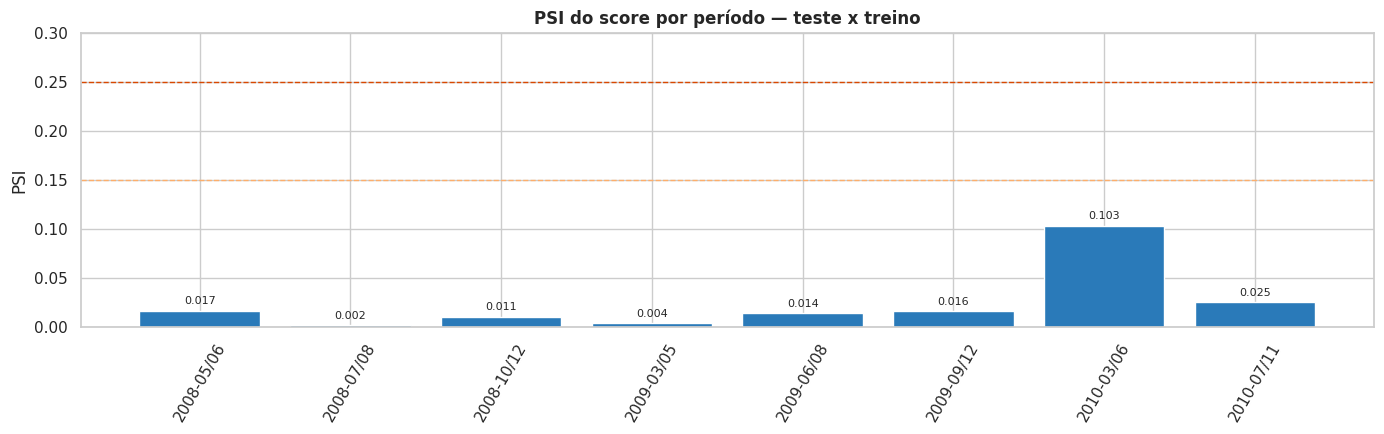

,qtd_treino,qtd_teste,psi,status
periodo,,,,
2008-05/06,"8,460","3,676",0.0169,Estável
2008-07/08,"8,334","3,520",0.0025,Estável
2008-10/12,"2,570","1,122",0.0108,Estável
2009-03/05,"5,961","2,571",0.0040,Estável
2009-06/08,"1,163",499,0.0140,Estável
2009-09/12,867,375,0.0161,Estável
2010-03/06,613,266,0.1035,Estável
2010-07/11,855,324,0.0255,Estável


Salvo em /content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Faixas de Risco


In [73]:
# ===== PSI do score por safra: teste x treino (mesma safra) =====
def classificar_psi(psi):
    return 'Estável' if psi < 0.15 else 'Atenção' if psi < 0.25 else 'Instável'

def calc_psi(ref, atual, n_bins=10):
    """PSI com faixas definidas por quantis da referência (treino da mesma safra)."""
    ref, atual = pd.Series(ref).dropna(), pd.Series(atual).dropna()
    cortes = np.unique(np.quantile(ref, np.linspace(0, 1, n_bins + 1)))
    cortes[0], cortes[-1] = -np.inf, np.inf          # valores fora da faixa do treino caem nas pontas
    p_ref = pd.cut(ref, cortes).value_counts(normalize=True, sort=False).clip(lower=1e-6)
    p_atu = pd.cut(atual, cortes).value_counts(normalize=True, sort=False).clip(lower=1e-6)
    return float(((p_atu - p_ref) * np.log(p_atu / p_ref)).sum())

def psi_por_safra(col_safra, min_qtd=100, n_bins=10):
    linhas = []
    for safra in sorted(set(base_scoradaTreino[col_safra]) & set(base_scoradaTeste[col_safra])):
        s_tr = base_scoradaTreino.loc[base_scoradaTreino[col_safra] == safra, 'score']
        s_te = base_scoradaTeste.loc[base_scoradaTeste[col_safra] == safra, 'score']
        bins = n_bins if len(s_te) >= 200 else 5         # safras pequenas: menos faixas para não ficar vazio
        linhas.append({col_safra: safra, 'qtd_treino': len(s_tr), 'qtd_teste': len(s_te),
                       'psi': calc_psi(s_tr, s_te, bins)})
    t = pd.DataFrame(linhas).set_index(col_safra)
    t['status'] = np.where(t['qtd_teste'] < min_qtd, 'Volume baixo', t['psi'].apply(classificar_psi))
    return t

def grafico_psi(t, titulo):
    cores = t['status'].map({'Estável': '#2a7ab9', 'Atenção': '#fdae6b', 'Instável': '#d94801', 'Volume baixo': '#bdbdbd'})
    fig, ax = plt.subplots(figsize=(14, 4.5))
    barras = ax.bar(t.index.astype(str), t['psi'], color=cores)
    ax.bar_label(barras, labels=[f'{v:.3f}' for v in t['psi']], padding=3, fontsize=8)
    for lim, cor in [(0.15, '#fdae6b'), (0.25, '#d94801')]:
        ax.axhline(lim, ls='--', color=cor, lw=1)
    ax.set_ylim(0, max(0.30, t.loc[t['status'] != 'Volume baixo', 'psi'].max() * 1.25))
    ax.set_title(titulo, fontweight='bold'); ax.set_ylabel('PSI')
    plt.setp(ax.get_xticklabels(), rotation=60)
    plt.tight_layout(); plt.show()

# 2. Por período agrupado (mais estável para leitura)
psi_periodo = psi_por_safra('periodo')
grafico_psi(psi_periodo, 'Estabilidade do público - PSI')
display(psi_periodo.style.format({'qtd_treino': '{:,.0f}', 'qtd_teste': '{:,.0f}', 'psi': '{:.4f}'}))

# 3. Salvar
with pd.ExcelWriter(f'{PASTA_FAIXARISCO}/psi_por_safra_teste_x_treino.xlsx') as writer:
    psi_anomes.to_excel(writer, sheet_name='por_AnoMes')
    psi_periodo.to_excel(writer, sheet_name='por_periodo')
print('Salvo em', PASTA_FAIXARISCO)

In [74]:
# ===== Tabelas para a simulação financeira (base de TESTE) =====
def resumo(base, col):
    t = base.groupby(col, observed=True).agg(qtd_publico=(TARGET, 'size'), qtd_converteram=(TARGET, 'sum'))
    t['pct_publico'] = t['qtd_publico'] / t['qtd_publico'].sum()
    t['taxa_conversao'] = t['qtd_converteram'] / t['qtd_publico']
    return t

# 1. Por período
tab_periodo = resumo(base_scoradaTeste, 'periodo')

# 2. Por faixa de propensão
tab_faixa = resumo(base_scoradaTeste, 'faixa_propensao')

# 3. Por decil (1 = maior score) — é a tabela mais útil para a simulação, por ser mais granular
base_scoradaTeste['decil'] = pd.qcut(base_scoradaTeste['score'].rank(method='first', ascending=False),
                                     10, labels=range(1, 11))
tab_decil = resumo(base_scoradaTeste, 'decil')
tab_decil['pct_publico_acum'] = tab_decil['pct_publico'].cumsum()
tab_decil['captura_acum'] = tab_decil['qtd_converteram'].cumsum() / tab_decil['qtd_converteram'].sum()
tab_decil['taxa_acum'] = tab_decil['qtd_converteram'].cumsum() / tab_decil['qtd_publico'].cumsum()

for nome, t in [('período', tab_periodo), ('faixa', tab_faixa), ('decil', tab_decil)]:
    print(f'\nPor {nome}')
    display(t.style.format({'qtd_publico': '{:,.0f}', 'qtd_converteram': '{:,.0f}', 'pct_publico': '{:.1%}',
                            'taxa_conversao': '{:.2%}', 'pct_publico_acum': '{:.0%}',
                            'captura_acum': '{:.1%}', 'taxa_acum': '{:.2%}'}))

with pd.ExcelWriter(f'{PASTA_FAIXARISCO}/tabelas_simulacao_financeira.xlsx') as writer:
    tab_periodo.to_excel(writer, sheet_name='por_periodo')
    tab_faixa.to_excel(writer, sheet_name='por_faixa')
    tab_decil.to_excel(writer, sheet_name='por_decil')
print('Salvo em', PASTA_FAIXARISCO)


Por período


,qtd_publico,qtd_converteram,pct_publico,taxa_conversao
periodo,,,,
2008-05/06,"3,676",126,29.8%,3.43%
2008-07/08,"3,520",187,28.5%,5.31%
2008-10/12,"1,122",60,9.1%,5.35%
2009-03/05,"2,571",348,20.8%,13.54%
2009-06/08,499,189,4.0%,37.88%
2009-09/12,375,170,3.0%,45.33%
2010-03/06,266,146,2.2%,54.89%
2010-07/11,324,166,2.6%,51.23%



Por faixa


,qtd_publico,qtd_converteram,pct_publico,taxa_conversao
faixa_propensao,,,,
1) Alta propensao,606,343,4.9%,56.60%
2) Media propensao,"7,613",875,61.6%,11.49%
3) Baixa propensao,"4,134",174,33.5%,4.21%



Por decil


,qtd_publico,qtd_converteram,pct_publico,taxa_conversao,pct_publico_acum,captura_acum,taxa_acum
decil,,,,,,,
1,"1,236",488,10.0%,39.48%,10%,35.1%,39.48%
2,"1,235",180,10.0%,14.57%,20%,48.0%,27.03%
3,"1,235",157,10.0%,12.71%,30%,59.3%,22.26%
4,"1,235",145,10.0%,11.74%,40%,69.7%,19.63%
5,"1,236",122,10.0%,9.87%,50%,78.4%,17.68%
6,"1,235",81,10.0%,6.56%,60%,84.3%,15.83%
7,"1,235",68,10.0%,5.51%,70%,89.2%,14.35%
8,"1,235",61,10.0%,4.94%,80%,93.5%,13.18%
9,"1,235",46,10.0%,3.72%,90%,96.8%,12.13%


Salvo em /content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Faixas de Risco


## Próximos passos

1. **Escolher o modelo final** pela comparação da seção 10.3 (LightGBM tunado × Gradient Boosting).
2. **Visões finais** com o modelo escolhido: KS ao longo do tempo (por `AnoMes`) treino × teste, ordenação por decil, faixas de propensão, distribuição das faixas por safra e taxa de conversão por faixa. Depois, escorar o **OOT** e repetir as visões.